In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
np.random.seed(42)

n = 50

platforms = ['Instagram', 'Facebook', 'YouTube', 'X']
content_types = ['Reel', 'Image', 'Video', 'Carousel']

df = pd.DataFrame({
    'Post_ID': range(1, n + 1),
    'Platform': np.random.choice(platforms, n),
    'Content_Type': np.random.choice(content_types, n),
    'Likes': np.random.randint(100, 5000, n),
    'Shares': np.random.randint(10, 1000, n),
    'Comments': np.random.randint(5, 500, n),
    'Reach': np.random.randint(1000, 20000, n),
    'Post_Date': pd.date_range(
        start='2026-01-01',
        periods=n,
        freq='D'
    )
})

df['Engagement_Rate'] = (
    (df['Likes'] + df['Shares'] + df['Comments'])
    / df['Reach']
) * 100

df['Total_Engagement'] = (
    df['Likes'] + df['Shares'] + df['Comments']
)

df.head()

,Post_ID,Platform,Content_Type,Likes,Shares,Comments,Reach,Post_Date
0,1,YouTube,Video,4898,700,120,19091,2026-01-01
1,2,X,Image,261,584,465,6791,2026-01-02
2,3,Instagram,Video,4397,873,237,5931,2026-01-03
3,4,YouTube,Carousel,2081,752,263,1202,2026-01-04
4,5,YouTube,Video,1095,250,363,12447,2026-01-05


In [4]:
df.to_csv('social_media_data.csv', index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [8]:
print("Dataset Shape:", df.shape)


Dataset Shape: (50, 10)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Post_ID           50 non-null     int64         
 1   Platform          50 non-null     object        
 2   Content_Type      50 non-null     object        
 3   Likes             50 non-null     int64         
 4   Shares            50 non-null     int64         
 5   Comments          50 non-null     int64         
 6   Reach             50 non-null     int64         
 7   Post_Date         50 non-null     datetime64[ns]
 8   Engagement_Rate   50 non-null     float64       
 9   Total_Engagement  50 non-null     int64         
dtypes: datetime64[ns](1), float64(1), int64(6), object(2)
memory usage: 4.0+ KB


In [10]:
df.describe()

,Post_ID,Likes,Shares,Comments,Reach,Post_Date,Engagement_Rate,Total_Engagement
count,50.00000,50.000,50.000000,50.00000,50.000000,50,50.000000,50.000000
mean,25.50000,2551.640,522.940000,254.04000,10207.760000,2026-01-25 12:00:00,51.303194,3328.620000
min,1.00000,164.000,37.000000,6.00000,1197.000000,2026-01-01 00:00:00,4.981151,728.000000
25%,13.25000,1100.250,304.000000,135.75000,5784.750000,2026-01-13 06:00:00,18.953993,1687.000000
50%,25.50000,2611.000,565.500000,233.00000,9509.000000,2026-01-25 12:00:00,36.707749,3395.000000
75%,37.75000,3973.000,706.000000,374.25000,15201.000000,2026-02-06 18:00:00,52.445077,4970.750000
max,50.00000,4987.000,967.000000,489.00000,19895.000000,2026-02-19 00:00:00,257.570715,5889.000000
std,14.57738,1610.294,259.785815,132.87265,5537.032033,NaN,52.987980,1642.837353


In [11]:
print("Platform Distribution:")
print(df['Platform'].value_counts())

print("\nContent Type Distribution:")
print(df['Content_Type'].value_counts())

Platform Distribution:
Platform
X            16
YouTube      13
Facebook     11
Instagram    10
Name: count, dtype: int64

Content Type Distribution:
Content_Type
Image       15
Carousel    14
Video       11
Reel        10
Name: count, dtype: int64


In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Post_ID             0
Platform            0
Content_Type        0
Likes               0
Shares              0
Comments            0
Reach               0
Post_Date           0
Engagement_Rate     0
Total_Engagement    0
dtype: int64

Duplicate Records:
0


In [13]:
df = df.drop_duplicates()

df = df.dropna()

df['Post_Date'] = pd.to_datetime(df['Post_Date'])

df = df[
    (df['Reach'] > 0) &
    (df['Likes'] >= 0) &
    (df['Shares'] >= 0) &
    (df['Comments'] >= 0)
]

print("Data cleaning completed!")
print("Final Dataset Shape:", df.shape)

Data cleaning completed!
Final Dataset Shape: (50, 10)


In [14]:
correlation = df[
    ['Likes', 'Shares', 'Comments',
     'Reach', 'Engagement_Rate']
].corr()

print(correlation)

                    Likes    Shares  Comments     Reach  Engagement_Rate
Likes            1.000000  0.181318 -0.272538 -0.002120         0.404904
Shares           0.181318  1.000000 -0.207882 -0.010661         0.164624
Comments        -0.272538 -0.207882  1.000000 -0.133433         0.058098
Reach           -0.002120 -0.010661 -0.133433  1.000000        -0.663687
Engagement_Rate  0.404904  0.164624  0.058098 -0.663687         1.000000


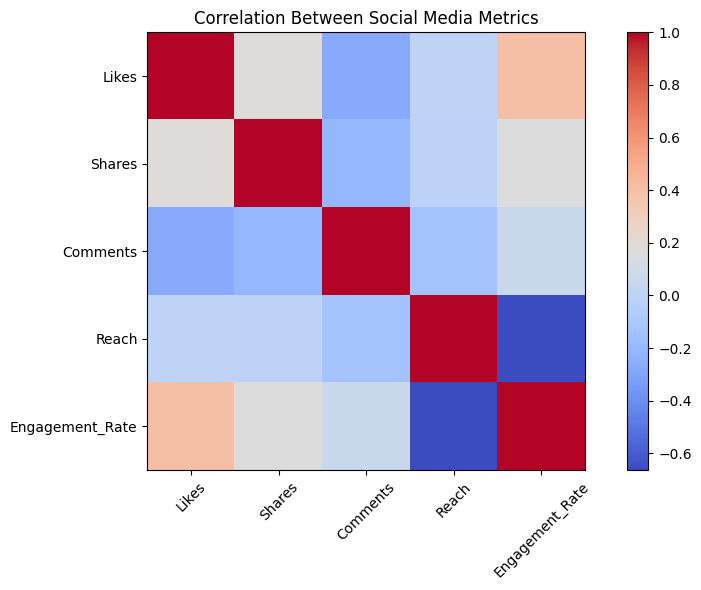

In [15]:
plt.figure(figsize=(9, 6))

plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Social Media Metrics")
plt.tight_layout()
plt.show()

In [16]:
platform_analysis = df.groupby('Platform').agg({
    'Likes': 'mean',
    'Shares': 'mean',
    'Comments': 'mean',
    'Reach': 'mean',
    'Engagement_Rate': 'mean'
}).round(2)

print(platform_analysis)

             Likes  Shares  Comments     Reach  Engagement_Rate
Platform                                                       
Facebook   2438.00  536.36    209.09   8670.09            65.01
Instagram  3036.10  532.70    327.70   7695.40            60.71
X          2341.94  493.94    273.38  12805.62            28.58
YouTube    2533.23  539.77    211.62  10244.08            60.44


In [17]:
content_analysis = df.groupby('Content_Type').agg({
    'Likes': 'sum',
    'Shares': 'sum',
    'Comments': 'sum',
    'Total_Engagement': 'sum'
})

print(content_analysis)

              Likes  Shares  Comments  Total_Engagement
Content_Type                                           
Carousel      39764    5830      3931             49525
Image         33479    8340      3716             45535
Reel          22954    5652      2397             31003
Video         31385    6325      2658             40368


In [18]:
daily_engagement = df.groupby('Post_Date')[
    'Total_Engagement'
].sum()

print(daily_engagement.head())

Post_Date
2026-01-01    5718
2026-01-02    1310
2026-01-03    5507
2026-01-04    3096
2026-01-05    1708
Name: Total_Engagement, dtype: int64


In [19]:
fig1 = px.bar(
    platform_analysis.reset_index(),
    x='Platform',
    y='Engagement_Rate',
    color='Platform',
    title='Which Social Media Platform Has the Highest Engagement Rate?',
    labels={
        'Engagement_Rate': 'Average Engagement Rate (%)'
    }
)

fig1.show()

In [20]:
fig2 = px.bar(
    content_analysis.reset_index(),
    x='Content_Type',
    y='Total_Engagement',
    color='Content_Type',
    title='Which Content Type Generates the Most Engagement?',
    labels={
        'Total_Engagement': 'Total Interactions'
    }
)

fig2.show()

In [21]:
fig3 = px.line(
    df.sort_values('Post_Date'),
    x='Post_Date',
    y='Total_Engagement',
    markers=True,
    title='Daily Social Media Engagement Trend'
)

fig3.update_layout(
    xaxis_title='Post Date',
    yaxis_title='Total Engagement'
)

fig3.show()

In [22]:
fig4 = px.scatter(
    df,
    x='Reach',
    y='Total_Engagement',
    color='Platform',
    size='Likes',
    hover_data=['Post_ID', 'Content_Type'],
    title='Does Higher Reach Lead to More Engagement?'
)

fig4.show()

In [23]:
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        'Average Engagement Rate by Platform',
        'Engagement by Content Type',
        'Daily Engagement Trend',
        'Reach vs Total Engagement'
    )
)

# Chart 1: Platform engagement
fig.add_trace(
    go.Bar(
        x=platform_analysis.index,
        y=platform_analysis['Engagement_Rate'],
        name='Engagement Rate'
    ),
    row=1, col=1
)

# Chart 2: Content type engagement
fig.add_trace(
    go.Bar(
        x=content_analysis.index,
        y=content_analysis['Total_Engagement'],
        name='Content Engagement'
    ),
    row=1, col=2
)

# Chart 3: Daily engagement trend
fig.add_trace(
    go.Scatter(
        x=df['Post_Date'],
        y=df['Total_Engagement'],
        mode='lines+markers',
        name='Daily Engagement'
    ),
    row=2, col=1
)

# Chart 4: Reach vs engagement
fig.add_trace(
    go.Scatter(
        x=df['Reach'],
        y=df['Total_Engagement'],
        mode='markers',
        text=df['Platform'],
        name='Reach Analysis'
    ),
    row=2, col=2
)

fig.update_layout(
    title_text='Social Media Engagement and Content Performance Dashboard',
    height=850,
    width=1200,
    template='plotly_white',
    showlegend=True
)

fig.show()

In [24]:
fig.write_html(
    'Social_Media_Analytics_Dashboard.html'
)

print("Interactive dashboard exported successfully!")

Interactive dashboard exported successfully!


In [27]:
from google.colab import files

files.download('Social_Media_Analytics_Dashboard.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>